# Mask R-CNN — Customized training on FoodSeg103

**Model:** torchvision `maskrcnn_resnet50_fpn_v2`, COCO-pretrained, with its box and mask heads replaced by a
**class-agnostic** head (`num_classes=2`: background + food). Each food-class region of a FoodSeg103 label mask
(area ≥ 100 px) is one instance. Images are used **as-is** (no `FoodImagePreprocessor`) — the main difference from
`MaskRCNN.ipynb`.

**Training:** AdamW + OneCycle for 10 epochs, frozen BatchNorm, flip/affine/colour-jitter augmentation, with a
10-image overfit check first; the best checkpoint is picked by val F1@50.

**Threshold selection:** NMS and score threshold are swept on **val**; `CHOSEN` is filled in **by hand** from the
sweep (Step 7a), then test is run once.

Outputs: `outputs/maskrcnn_custom_test.pkl` for `compare_models.ipynb`; checkpoints, sweep and
`maskrcnn_cust_v01.pt` in `runs/custom1/`

## 1 Library

In [3]:
import sys, platform, json, math, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torchvision
import matplotlib.pyplot as plt
from PIL import Image

# FoodSeg103 paths, split files and mask loading (playground/foodseg_common.py)
import foodseg_common as fc

## 2 Configuration

In [13]:
# ── paths ──────────────────────────────────────────────────────────────────
# FoodSeg103: dataset/foodseg103/Images/{img_dir,ann_dir}/{train,val,test} + ImageSets/{split}.txt
DATA_ROOT = fc.DATA_ROOT
RUN_NAME  = 'custom1'
RUN_DIR   = fc.PLAYGROUND / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ('train', 'val', 'test')

# ── hyper-parameters ─────────────────────────────────────────────────────────
CFG = dict(
    arch        = 'v2',    # 'v1' or 'v2' (resnet50_fpn_v2 is stronger)
    epochs      = 10,
    batch_size  = 2,
    lr          = 5e-4,
    min_size    = 640,
    max_size    = 1024,
    seed        = 42,
    num_workers = 0,       # 0 is safe on Windows; raise on Linux if you have cores
    min_area    = 100,     # px; class regions smaller than this are skipped
    max_dets    = 30,      # max detections per image
    nms_thresh  = 0.6,
    score_thresh= 0.05,
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
print('data_root:', DATA_ROOT)
print('run_dir:', RUN_DIR)
for name in SPLITS:
    ids = fc.read_split_ids(name)
    img_dir = DATA_ROOT / 'Images' / 'img_dir' / name
    ann_dir = DATA_ROOT / 'Images' / 'ann_dir' / name
    print(f"  {name}: {len(ids)} ids  images={'OK' if img_dir.exists() else 'MISSING'}  "
          f"masks={'OK' if ann_dir.exists() else 'MISSING'}")

device: cuda
data_root: C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\dataset\foodseg103
run_dir: C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\runs\custom1
  train: 4982 ids  images=OK  masks=OK
  val: 1067 ids  images=OK  masks=OK
  test: 1069 ids  images=OK  masks=OK


## 3 Dataset, model, training loop, and evaluation

All definitions are in the cells below. Run them once; re-run only if you edit the code.

### 3a — Dataset

In [6]:
from torchvision import tv_tensors
from torchvision.transforms import v2 as T
from torchvision.transforms.v2 import functional as TF
from torch.utils.data import DataLoader


def _get_transforms(augment: bool):
    ops = []
    if augment:
        ops += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.85, 1.15)),
            T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.02),
        ]
    ops += [T.ToDtype(torch.float32, scale=True), T.SanitizeBoundingBoxes(min_size=4)]
    return T.Compose(ops)


class FoodDataset(torch.utils.data.Dataset):
    """FoodSeg103 split. Each food-class region of the PNG label mask is one instance with label=1 ('food')."""

    def __init__(self, split, augment=False, min_area=100, limit=None):
        self.split    = split
        self.min_area = min_area
        ids = fc.read_split_ids(split)            # ids without extension, e.g. '00006130'
        self.ids       = ids[:limit] if limit else ids
        self.transform = _get_transforms(augment)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        sample_id = self.ids[idx]

        # ---- image
        img = Image.open(fc.image_path(self.split, sample_id)).convert('RGB')
        w, h = img.size

        # ---- masks & boxes: one instance per non-zero class id in the label PNG
        label_mask = fc.load_label_mask(fc.mask_path(self.split, sample_id))
        masks, boxes = [], []
        for m in fc.gt_instances(label_mask, self.min_area):
            if m.shape != (h, w):
                continue
            ys, xs = np.nonzero(m)
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
            masks.append(m.astype(np.uint8))

        if masks:
            masks_t = torch.from_numpy(np.stack(masks)).to(torch.uint8)
            boxes_t = torch.tensor(boxes, dtype=torch.float32)
        else:
            masks_t = torch.zeros((0, h, w), dtype=torch.uint8)
            boxes_t = torch.zeros((0, 4),    dtype=torch.float32)

        img_t  = tv_tensors.Image(TF.pil_to_tensor(img))
        target = {
            'boxes':    tv_tensors.BoundingBoxes(boxes_t, format='XYXY', canvas_size=(h, w)),
            'masks':    tv_tensors.Mask(masks_t),
            'labels':   torch.ones(len(masks), dtype=torch.int64),
            'image_id': idx,
        }
        return self.transform(img_t, target)


def collate_fn(batch):
    return tuple(zip(*batch))


def _targets_to_device(targets, dev):
    """Move target dicts to device, stripping tv_tensor wrappers."""
    out = []
    for t in targets:
        out.append({
            'boxes':  t['boxes'].as_subclass(torch.Tensor).to(dev),
            'masks':  t['masks'].as_subclass(torch.Tensor).to(dev),
            'labels': t['labels'].to(dev),
        })
    return out


print('Dataset class defined.')

Dataset class defined.


### 3b — Model

In [7]:
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights,
    maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn  import MaskRCNNPredictor
from torch import nn


def build_model(
    num_classes=2,
    arch='v2',
    pretrained=True,
    min_size=640,
    max_size=1024,
    trainable_backbone_layers=3,
    max_detections=30,
    nms_thresh=0.6,
    score_thresh=0.05,
):
    kw = dict(
        min_size=min_size, max_size=max_size,
        box_detections_per_img=max_detections,
        box_nms_thresh=nms_thresh,
        box_score_thresh=score_thresh,
    )
    if arch == 'v2':
        fn, W = maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights
    else:
        fn, W = maskrcnn_resnet50_fpn,    MaskRCNN_ResNet50_FPN_Weights

    model = fn(
        weights=W.COCO_V1 if pretrained else None,
        weights_backbone=None if pretrained else None,
        trainable_backbone_layers=trainable_backbone_layers,
        **kw,
    )
    # replace heads for our class count
    in_box  = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor  = FastRCNNPredictor(in_box, num_classes)
    in_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_mask, 256, num_classes)
    return model


def freeze_bn(model):
    """Keep BatchNorm in eval mode (v2 BN heads are noisy at batch_size=2)."""
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()
            for p in m.parameters():
                p.requires_grad_(False)


print('Model builder defined.')

Model builder defined.


### 3c — Evaluation

In [8]:
@torch.no_grad()
def collect(model, loader, dev, base_score=0.3, mask_thr=0.5, nms=None):
    """
    Run model over loader and cache per-image IoU arrays.
    Returns a list of dicts; no need to re-run inference for different score thresholds.
    """
    model.eval()
    old_nms = model.roi_heads.nms_thresh
    if nms is not None:
        model.roi_heads.nms_thresh = nms

    cache = []
    for imgs, targets in loader:
        imgs_d = [i.to(dev) for i in imgs]
        preds  = model(imgs_d)
        for pred, tgt in zip(preds, targets):
            keep   = pred['scores'] >= base_score
            pm     = (pred['masks'][keep, 0] > mask_thr)      # pred masks (P, H, W)
            gm     = tgt['masks'].as_subclass(torch.Tensor).to(dev).bool()  # gt masks (G, H, W)
            scores = pred['scores'][keep].cpu().numpy()

            if pm.shape[0] == 0 or gm.shape[0] == 0:
                cache.append(dict(scores=scores, iou=np.zeros((len(scores), len(gm))),
                                  n_gt=len(gm)))
                continue

            p = pm.flatten(1).float()
            g = gm.flatten(1).float()
            inter = p @ g.T
            pa, ga = p.sum(1), g.sum(1)
            iou = inter / (pa[:, None] + ga[None, :] - inter).clamp(min=1)
            cache.append(dict(scores=scores, iou=iou.cpu().numpy(), n_gt=len(gm)))

    model.roi_heads.nms_thresh = old_nms
    return cache


def _greedy_match(iou, thr):
    """One-to-one greedy assignment; returns list of (pred_idx, gt_idx) pairs."""
    if iou.size == 0:
        return []
    ii, jj = np.nonzero(iou >= thr)
    used_p, used_g, pairs = set(), set(), []
    for k in np.argsort(-iou[ii, jj]):
        i, j = int(ii[k]), int(jj[k])
        if i in used_p or j in used_g:
            continue
        used_p.add(i); used_g.add(j)
        pairs.append((i, j))
    return pairs


def metrics(cache, score_thr, iou_thrs=(0.5, 0.75)):
    """Compute precision, recall, F1 at each IoU threshold."""
    stats = {t: dict(tp=0, fp=0, fn=0) for t in iou_thrs}
    for c in cache:
        keep = c['scores'] >= score_thr
        iou  = c['iou'][keep]
        n_gt = c['n_gt']
        for t in iou_thrs:
            pairs = _greedy_match(iou, t)
            s = stats[t]
            s['tp'] += len(pairs)
            s['fp'] += iou.shape[0] - len(pairs)
            s['fn'] += n_gt - len(pairs)
    res = {}
    for t in iou_thrs:
        n = int(round(t * 100))
        s = stats[t]
        p = s['tp'] / max(1, s['tp'] + s['fp'])
        r = s['tp'] / max(1, s['tp'] + s['fn'])
        f = 2 * p * r / max(1e-9, p + r)
        res[f'precision@{n}'] = p
        res[f'recall@{n}']    = r
        res[f'f1@{n}']        = f
    return res


print('Evaluation helpers defined.')

Evaluation helpers defined.


### 3d — Training loop

In [9]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def make_loader(split, augment=False, limit=None):
    ds  = FoodDataset(split, augment=augment,
                      min_area=CFG['min_area'], limit=limit)
    return DataLoader(ds, batch_size=CFG['batch_size'],
                      shuffle=augment, collate_fn=collate_fn,
                      num_workers=CFG['num_workers'], pin_memory=False)


def new_model():
    m = build_model(
        arch=CFG['arch'], pretrained=True,
        min_size=CFG['min_size'], max_size=CFG['max_size'],
        max_detections=CFG['max_dets'],
        nms_thresh=CFG['nms_thresh'],
        score_thresh=CFG['score_thresh'],
    )
    return m.to(device)


def fit(model, train_loader, val_loader, epochs, tag):
    opt = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=CFG['lr'], weight_decay=1e-4,
    )
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=CFG['lr'],
        steps_per_epoch=len(train_loader), epochs=epochs,
    )

    best_f1, history = 0.0, []

    for ep in range(1, epochs + 1):
        # ---- train
        model.train()
        freeze_bn(model)
        t0 = time.time()
        total_loss = 0.0

        for imgs, targets in train_loader:
            imgs_d = [i.to(device) for i in imgs]
            tgts_d = _targets_to_device(targets, device)
            loss_dict = model(imgs_d, tgts_d)
            loss = sum(loss_dict.values())
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        elapsed  = time.time() - t0
        peak_gb  = torch.cuda.max_memory_allocated(device) / 1e9 if device.type == 'cuda' else 0

        # ---- validate
        cache = collect(model, val_loader, device)
        m = metrics(cache, score_thr=0.5)
        f1 = m['f1@50']
        lr = sched.get_last_lr()[0]

        row = dict(epoch=ep, loss=avg_loss, lr=lr, sec=elapsed, peak_gb=peak_gb, **m)
        history.append(row)

        print(f'ep {ep:3d}/{epochs}  loss={avg_loss:.4f}  '
              f'F1@50={f1:.3f}  P@50={m["precision@50"]:.3f}  '
              f'R@50={m["recall@50"]:.3f}  lr={lr:.2e}  '
              f'{elapsed:.0f}s  {peak_gb:.2f}GB')

        # ---- save best
        if f1 >= best_f1:
            best_f1 = f1
            torch.save(dict(epoch=ep, model=model.state_dict(),
                            config=CFG, metrics=m),
                       RUN_DIR / f'{tag}_best.pt')

        # ---- save last (for resume)
        torch.save(dict(epoch=ep, model=model.state_dict(),
                        config=CFG, metrics=m),
                   RUN_DIR / f'{tag}_last.pt')

    # save history
    (RUN_DIR / f'{tag}_history.json').write_text(json.dumps(history, indent=2))
    print(f'Done. Best val F1@50 = {best_f1:.3f}')
    return history


print('Training loop defined.')

Training loop defined.


## 4 Training
  
Set `OVERFIT = True` to train on 10 images for 60 epochs.  
Set `OVERFIT = False` to run full training directly.

In [10]:
OVERFIT = True   # set True for a quick sanity check before the full run

set_seed(CFG['seed'])

if OVERFIT:
    print('Running overfit test on 10 train images...')
    tl = make_loader('train', augment=False, limit=10)
    vl = make_loader('train', augment=False, limit=10)  # score on the same 10
    model = new_model()
    h = fit(model, tl, vl, epochs=30, tag='overfit')
    print('GATE:', 'PASS' if h[-1]['f1@50'] >= 0.9 else 'FAIL',
          '(final F1@50 =', round(h[-1]['f1@50'], 3), ')')
else:
    print('Skipping overfit test. Set OVERFIT=True to run it.')

Running overfit test on 10 train images...
ep   1/30  loss=2.1990  F1@50=0.000  P@50=0.000  R@50=0.000  lr=3.51e-05  11s  3.55GB
ep   2/30  loss=1.3288  F1@50=0.441  P@50=0.619  R@50=0.342  lr=7.86e-05  2s  3.59GB
ep   3/30  loss=1.0056  F1@50=0.416  P@50=0.276  R@50=0.842  lr=1.45e-04  2s  3.69GB
ep   4/30  loss=0.7094  F1@50=0.386  P@50=0.250  R@50=0.842  lr=2.26e-04  2s  3.70GB
ep   5/30  loss=0.6777  F1@50=0.392  P@50=0.261  R@50=0.789  lr=3.11e-04  2s  3.70GB
ep   6/30  loss=0.8334  F1@50=0.252  P@50=0.153  R@50=0.711  lr=3.90e-04  2s  3.70GB
ep   7/30  loss=0.8576  F1@50=0.386  P@50=0.265  R@50=0.711  lr=4.52e-04  3s  3.70GB
ep   8/30  loss=0.8965  F1@50=0.309  P@50=0.207  R@50=0.605  lr=4.90e-04  2s  3.70GB
ep   9/30  loss=1.2068  F1@50=0.190  P@50=0.108  R@50=0.763  lr=5.00e-04  2s  3.70GB
ep  10/30  loss=1.0006  F1@50=0.201  P@50=0.118  R@50=0.658  lr=4.96e-04  2s  3.70GB
ep  11/30  loss=0.7387  F1@50=0.337  P@50=0.216  R@50=0.763  lr=4.87e-04  2s  3.70GB
ep  12/30  loss=0.773

In [14]:
set_seed(CFG['seed'])

train_loader = make_loader('train', augment=True)
val_loader   = make_loader('val',   augment=False)

print(f'train batches: {len(train_loader)}  val batches: {len(val_loader)}')

model = new_model()
history = fit(model, train_loader, val_loader, epochs=CFG['epochs'], tag=RUN_NAME)

train batches: 2491  val batches: 534
ep   1/10  loss=0.7707  F1@50=0.398  P@50=0.273  R@50=0.732  lr=1.40e-04  3569s  5.82GB
ep   2/10  loss=0.8555  F1@50=0.415  P@50=0.314  R@50=0.612  lr=3.80e-04  3443s  7.10GB
ep   3/10  loss=0.8753  F1@50=0.413  P@50=0.298  R@50=0.672  lr=5.00e-04  3467s  7.10GB
ep   4/10  loss=0.8505  F1@50=0.384  P@50=0.267  R@50=0.682  lr=4.75e-04  3440s  7.10GB
ep   5/10  loss=0.8119  F1@50=0.361  P@50=0.243  R@50=0.697  lr=4.06e-04  3476s  7.10GB
ep   6/10  loss=0.7866  F1@50=0.449  P@50=0.333  R@50=0.690  lr=3.06e-04  3462s  7.10GB
ep   7/10  loss=0.7473  F1@50=0.441  P@50=0.324  R@50=0.690  lr=1.94e-04  3484s  7.10GB
ep   8/10  loss=0.7151  F1@50=0.459  P@50=0.339  R@50=0.712  lr=9.41e-05  3518s  7.10GB
ep   9/10  loss=0.6778  F1@50=0.462  P@50=0.340  R@50=0.718  lr=2.47e-05  3468s  7.10GB
ep  10/10  loss=0.6661  F1@50=0.462  P@50=0.343  R@50=0.711  lr=2.00e-09  3536s  7.10GB
Done. Best val F1@50 = 0.462


## 5 Training curves

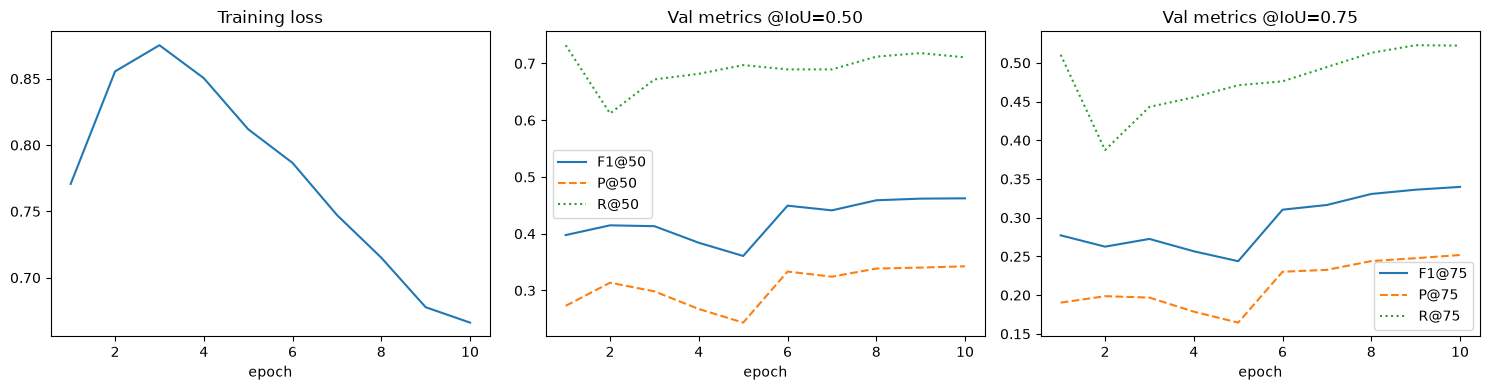

Best epoch: 10 | F1@50 = 0.462


In [15]:
import pandas as pd

hist_path = RUN_DIR / f'{RUN_NAME}_history.json'
hist = pd.DataFrame(json.loads(hist_path.read_text()))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist['epoch'], hist['loss'])
axes[0].set_title('Training loss'); axes[0].set_xlabel('epoch')

axes[1].plot(hist['epoch'], hist['f1@50'],        label='F1@50')
axes[1].plot(hist['epoch'], hist['precision@50'], label='P@50', linestyle='--')
axes[1].plot(hist['epoch'], hist['recall@50'],    label='R@50', linestyle=':')
axes[1].set_title('Val metrics @IoU=0.50'); axes[1].legend(); axes[1].set_xlabel('epoch')

axes[2].plot(hist['epoch'], hist['f1@75'],        label='F1@75')
axes[2].plot(hist['epoch'], hist['precision@75'], label='P@75', linestyle='--')
axes[2].plot(hist['epoch'], hist['recall@75'],    label='R@75', linestyle=':')
axes[2].set_title('Val metrics @IoU=0.75'); axes[2].legend(); axes[2].set_xlabel('epoch')

plt.tight_layout()
plt.savefig(RUN_DIR / f'{RUN_NAME}_curves.png', dpi=120)
plt.show()
print('Best epoch:', hist.loc[hist['f1@50'].idxmax(), 'epoch'],
      '| F1@50 =', round(hist['f1@50'].max(), 3))

## 6 Threshold sweep on validation set

Load the best checkpoint, run inference once per NMS setting, then score across many score thresholds without re-running the model. Pick the score threshold that maximises F1@50.

In [16]:
# load best checkpoint
ckpt = torch.load(RUN_DIR / f'{RUN_NAME}_best.pt', map_location='cpu', weights_only=True)
model = new_model()   # fresh model with correct arch
model.load_state_dict(ckpt['model'])
model = model.to(device).eval()
print('Loaded best checkpoint: epoch', ckpt['epoch'])

val_loader_eval = make_loader('val', augment=False)

NMS_GRID   = (0.6, 0.5, 0.4, 0.3)
SCORE_GRID = np.arange(0.30, 1.00, 0.05)

rows = []
for nms in NMS_GRID:
    print(f'  running NMS={nms} ...', end=' ')
    cache = collect(model, val_loader_eval, device, nms=nms)
    for thr in SCORE_GRID:
        m = metrics(cache, score_thr=float(thr))
        rows.append(dict(nms=nms, score_thr=round(float(thr), 2), **m))
    print('done')

sweep = pd.DataFrame(rows)
sweep.to_csv(RUN_DIR / 'val_threshold_sweep.csv', index=False)
print('\nTop 10 by F1@50:')
print(sweep.nlargest(10, 'f1@50')[['nms', 'score_thr', 'f1@50', 'precision@50', 'recall@50']].to_string(index=False))

Loaded best checkpoint: epoch 10
  running NMS=0.6 ... done
  running NMS=0.5 ... done
  running NMS=0.4 ... done
  running NMS=0.3 ... done

Top 10 by F1@50:
 nms  score_thr    f1@50  precision@50  recall@50
 0.4       0.85 0.643172      0.708093   0.589155
 0.4       0.80 0.641844      0.676159   0.610845
 0.3       0.80 0.637758      0.713128   0.576797
 0.4       0.75 0.635306      0.644116   0.626734
 0.3       0.75 0.635097      0.685055   0.591929
 0.4       0.90 0.634930      0.744739   0.553342
 0.3       0.85 0.633880      0.737370   0.555864
 0.3       0.70 0.631078      0.662781   0.602270
 0.5       0.85 0.630025      0.659856   0.602774
 0.4       0.70 0.626969      0.616943   0.637327


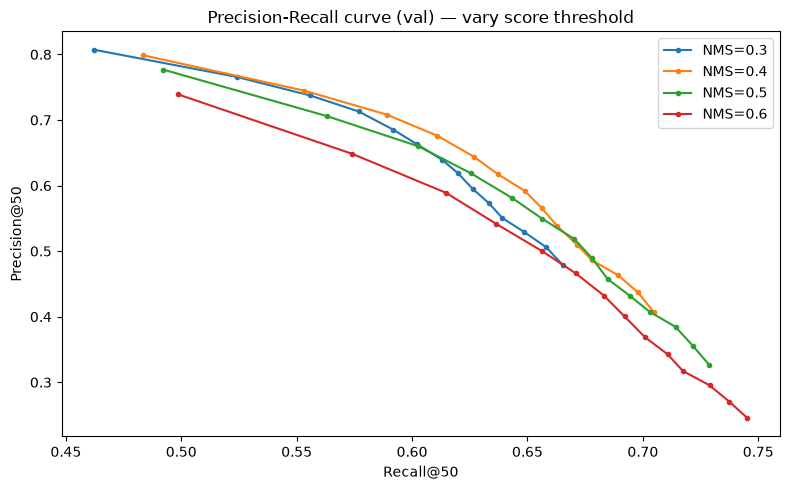

In [17]:
# plot precision-recall trade-off for each NMS setting
fig, ax = plt.subplots(figsize=(8, 5))
for nms, grp in sweep.groupby('nms'):
    grp = grp.sort_values('recall@50')
    ax.plot(grp['recall@50'], grp['precision@50'], marker='.', label=f'NMS={nms}')
ax.set_xlabel('Recall@50'); ax.set_ylabel('Precision@50')
ax.set_title('Precision-Recall curve (val) — vary score threshold')
ax.legend(); plt.tight_layout(); plt.show()

## 7a Test evaluation

Fill in `CHOSEN` from Step 6 (e.g. the NMS+score_thr that maximised F1@50 on validation). **Run this only once.**

In [24]:
CHOSEN = dict(
    score_thr = 0.70,   # <- fill in, e.g. 0.80
    nms       = 0.3,   # <- fill in, e.g. 0.4
)
SELECTION_RULE = 'Min F1@50 on val'   # <- brief note, e.g. 'max F1@50 on val'

assert CHOSEN['score_thr'] is not None and CHOSEN['nms'] is not None, \
    'Fill in CHOSEN from the sweep results above before running this cell.'

test_loader = make_loader('test', augment=False)
test_cache  = collect(model, test_loader, device, nms=CHOSEN['nms'])
test_m      = metrics(test_cache, score_thr=CHOSEN['score_thr'])

result = dict(**CHOSEN, rule=SELECTION_RULE, **test_m)
(RUN_DIR / 'test_result.json').write_text(json.dumps(result, indent=2))

print('Test results:')
for k, v in result.items():
    print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

OSError: broken data stream when reading image file

Test results:
  score_thr: 0.7000
  nms: 0.3000
  rule: Min F1@50 on val
  precision@50: 0.6483
  recall@50: 0.5965
  f1@50: 0.6213
  precision@75: 0.4666
  recall@75: 0.4293
  f1@75: 0.4472

In [25]:
CHOSEN = dict(
    score_thr = 0.85,    # Filled from the top sweep result
    nms       = 0.4,     # Filled from the top sweep result
)
SELECTION_RULE = 'max F1@50 on val'

assert CHOSEN['score_thr'] is not None and CHOSEN['nms'] is not None, \
    'Fill in CHOSEN from the sweep results above before running this cell.'

# 1. Load the test dataset (without augmentation)
test_loader = make_loader('test', augment=False)

# 2. Collect model predictions on the test set using the chosen NMS threshold
test_cache  = collect(model, test_loader, device, nms=CHOSEN['nms'])

# 3. Compute final metrics using the chosen confidence score threshold
test_m      = metrics(test_cache, score_thr=CHOSEN['score_thr'])

# 4. Save results to a JSON file in your run directory
result = dict(**CHOSEN, rule=SELECTION_RULE, **test_m)
(RUN_DIR / 'test_result.json').write_text(json.dumps(result, indent=2))

# 5. Print out the final test performance
print('Test results:')
for k, v in result.items():
    print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

Test results:
  score_thr: 0.8500
  nms: 0.4000
  rule: max F1@50 on val
  precision@50: 0.7081
  recall@50: 0.5870
  f1@50: 0.6419
  precision@75: 0.5120
  recall@75: 0.4245
  f1@75: 0.4641


## 7b Export test predictions

Runs the model over the test split with the `CHOSEN` NMS, saves the masks and scores to
`outputs/maskrcnn_custom_test.pkl`, and scores them with the same shared metrics (AP, P/R/F1, coverage, FG-IoU)
used for the other models. Run after Step 7.

In [26]:
@torch.no_grad()
def export_preds(model, split, nms, mask_thr=0.5):
    """Run the model over a split and return a foodseg_common prediction cache (RLE masks + scores)."""
    model.eval()
    old_nms = model.roi_heads.nms_thresh
    model.roi_heads.nms_thresh = nms
    loader = make_loader(split, augment=False)
    ids = loader.dataset.ids
    preds, t0 = {}, time.time()
    for imgs, targets in loader:
        out = model([i.to(device) for i in imgs])
        for img, pred, tgt in zip(imgs, out, targets):
            h, w = img.shape[-2:]
            pm = (pred['masks'][:, 0] > mask_thr).cpu().numpy()
            preds[ids[int(tgt['image_id'])]] = dict(h=int(h), w=int(w), rle=fc.encode_masks(pm),
                                                    scores=pred['scores'].cpu().numpy())
    model.roi_heads.nms_thresh = old_nms
    return preds, (time.time() - t0) / max(1, len(preds))


# ---- export test predictions (uses CHOSEN from Step 7) and score with the shared metrics
EXPORT_PATH = fc.OUT_ROOT / 'maskrcnn_custom_test.pkl'
custom_preds, custom_sec = export_preds(model, 'test', nms=CHOSEN['nms'])
fc.save_preds(custom_preds, EXPORT_PATH,
              meta=dict(model='Mask R-CNN (customized)', checkpoint=str(RUN_DIR / f'{RUN_NAME}_best.pt'),
                        sec_per_image=custom_sec, rule=SELECTION_RULE, **CHOSEN))
print(f'Saved {len(custom_preds)} test predictions to {EXPORT_PATH} ({custom_sec:.3f}s/img)')

custom_m = fc.evaluate(custom_preds, 'test', score_thr=CHOSEN['score_thr'])
(RUN_DIR / 'test_result_shared.json').write_text(json.dumps({**custom_m, **CHOSEN, 'rule': SELECTION_RULE}, indent=2))
print('Shared-metric test results (same evaluation as compare_models.ipynb):')
for k, v in custom_m.items():
    print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

Saved 1069 test predictions to C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\outputs\maskrcnn_custom_test.pkl (0.267s/img)
Shared-metric test results (same evaluation as compare_models.ipynb):
  n_images: 1069
  score_thr: 0.8500
  AP: 0.3142
  AP50: 0.5632
  AP75: 0.2971
  AP_small: 0.0097
  AP_medium: 0.1655
  AP_large: 0.3538
  AR1: 0.1472
  AR10: 0.4867
  AR100: 0.4983
  precision@50: 0.7081
  recall@50: 0.5870
  f1@50: 0.6419
  precision@75: 0.5120
  recall@75: 0.4245
  f1@75: 0.4641
  gt_coverage_mean: 0.6859
  gt_coverage_at50: 0.7463
  fg_iou_mean: 0.7568
  fg_iou_pixel: 0.7578
  preds_per_image: 3.0384


Saved 1069 test predictions to C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\outputs\maskrcnn_custom_test.pkl (0.244s/img)
Shared-metric test results (same evaluation as compare_models.ipynb):
  n_images: 1069
  score_thr: 0.7000
  AP: 0.3024
  AP50: 0.5412
  AP75: 0.2858
  AP_small: 0.0108
  AP_medium: 0.1683
  AP_large: 0.3385
  AR1: 0.1472
  AR10: 0.4664
  AR100: 0.4722
  precision@50: 0.6483
  recall@50: 0.5965
  f1@50: 0.6213
  precision@75: 0.4666
  recall@75: 0.4293
  f1@75: 0.4472
  gt_coverage_mean: 0.6632
  gt_coverage_at50: 0.7062
  fg_iou_mean: 0.7595
  fg_iou_pixel: 0.7564
  preds_per_image: 3.3723

## 8 Visualise test predictions

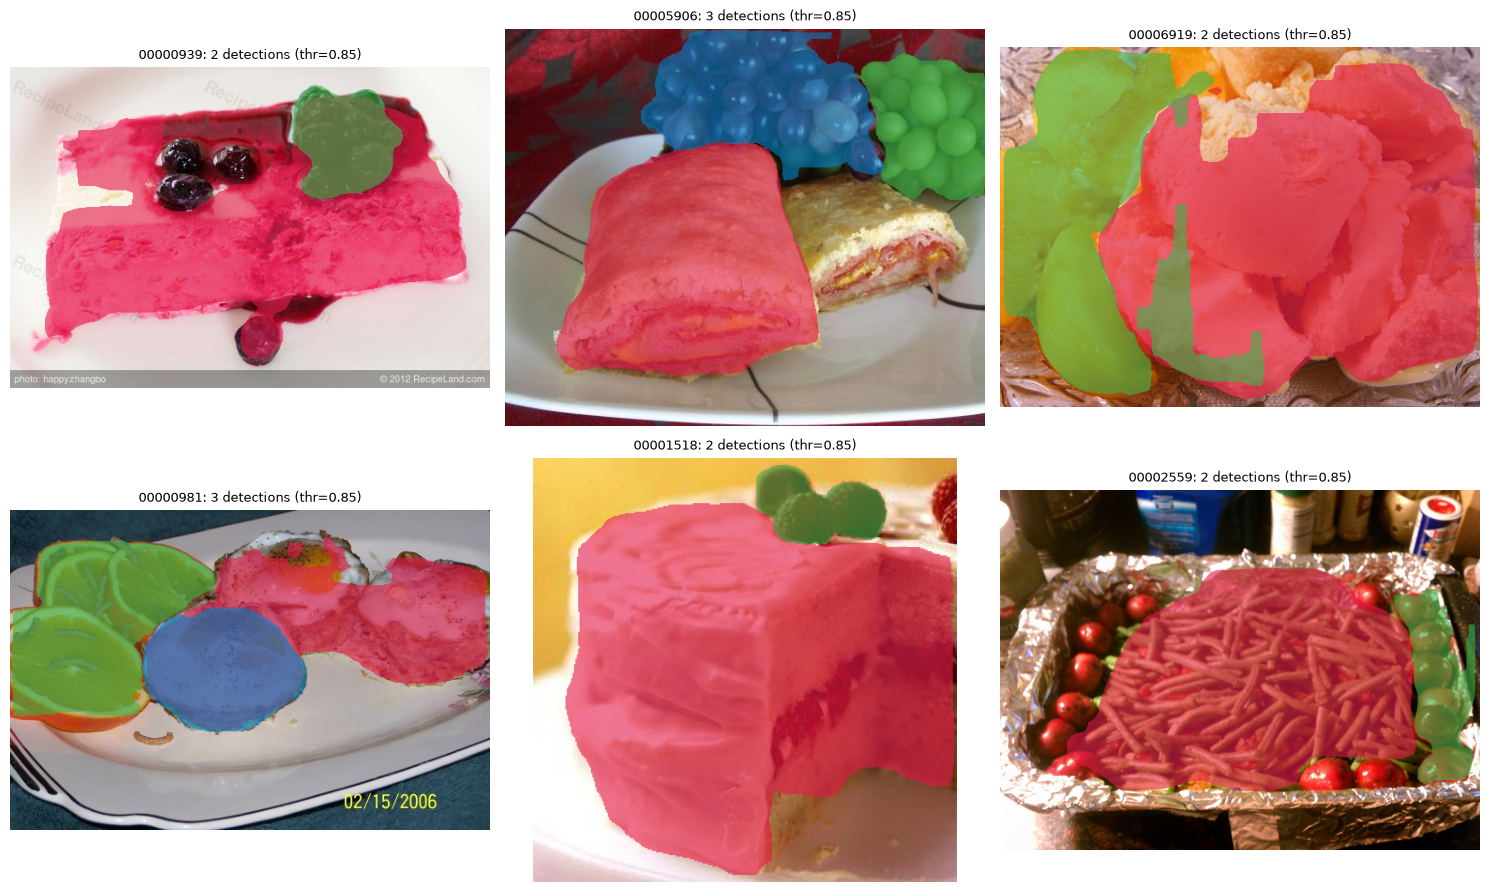

In [27]:
def show_prediction(img_tensor, pred, score_thr=0.5, mask_thr=0.5, max_masks=10):
    PALETTE = np.array([[230,25,75],[60,180,75],[0,130,200],
                         [245,130,48],[145,30,180],[70,200,200]], dtype=np.uint8)
    arr = img_tensor.permute(1, 2, 0).cpu().numpy()
    if arr.max() <= 1:
        arr = (arr * 255).astype(np.uint8)
    overlay = arr.copy()
    keep = (pred['scores'] >= score_thr).nonzero(as_tuple=True)[0]
    for i, idx in enumerate(keep[:max_masks]):
        m = (pred['masks'][idx, 0] > mask_thr).cpu().numpy()
        colour = PALETTE[i % len(PALETTE)]
        overlay[m] = (overlay[m] * 0.4 + colour * 0.6).astype(np.uint8)
    return overlay


test_ds = FoodDataset('test', augment=False, min_area=CFG['min_area'])

model.roi_heads.nms_thresh = CHOSEN.get('nms', CFG['nms_thresh'])
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, idx in zip(axes.flat, random.sample(range(len(test_ds)), min(6, len(test_ds)))):
    img_t, _ = test_ds[idx]          # already float32 in [0, 1] (ToDtype scale=True)
    with torch.no_grad():
        pred = model([img_t.to(device)])[0]
    thr = CHOSEN.get('score_thr', 0.5)
    ax.imshow(show_prediction(img_t, pred, score_thr=thr))
    n = int((pred['scores'] >= thr).sum())
    ax.set_title(f'{test_ds.ids[idx]}: {n} detections (thr={thr})', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

## 9 Final checkpoint

In [28]:
assert CHOSEN['score_thr'] is not None, 'Complete Step 7 first'

final = torch.load(RUN_DIR / f'{RUN_NAME}_best.pt', map_location='cpu', weights_only=True)
final['config'].update({
    'score_thr': CHOSEN['score_thr'],
    'nms':       CHOSEN['nms'],
    'selection_rule': SELECTION_RULE,
})
out = RUN_DIR / 'maskrcnn_cust_v01.pt'
torch.save(final, out)
print('Saved:', out)
print('Contents:', list(final.keys()))

Saved: C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\runs\custom1\maskrcnn_cust_v01.pt
Contents: ['epoch', 'model', 'config', 'metrics']
